In [1]:
# Imports
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

## 1. Inventario

In [15]:
DATA = Path("C:\Python\Proyectos_GitHub\PSIB2026Q2-TPI-Grupo07-Barboza-Casais-Mitchelena\data\multiple-sclerosis\MS")
CARPETAS = {
    "Control Axial_crop":    ("Control", "Axial"),
    "Control Saggital_crop": ("Control", "Sagital"),
    "MS Axial_crop":         ("MS", "Axial"),
    "MS Saggital_crop":      ("MS", "Sagital"),
}

filas = [{"ruta": p, "Clase": c, "Corte": k, "ext": p.suffix.lower()}
         for carpeta, (c, k) in CARPETAS.items()
         for p in sorted((DATA / carpeta).iterdir())]
df = pd.DataFrame(filas)

print(df.groupby(["Clase", "Corte"]).size().unstack())
print("\nTotal de fotos:", len(df))
print("Extensión de los datos: ")
df["ext"].value_counts().to_frame()

Corte    Axial  Sagital
Clase                  
Control   1002     1014
MS         650      761

Total de fotos: 3427
Extensión de los datos: 


,count
ext,
.png,3427


&nbsp; Las fotos tienen todas extensión .png, un método de compresión sin périda por lo que no vamos a tener problema con artefactos de compresión previos. El dataset contiene resonáncias (MRI) en FLAIR en dos cortes: axial y sagital. Además, los datos se dividen en dos grupos:

* Control: sujetos sanos, 59 pacientes. 
* MS: sujetos con esclerosis múltiple, 72 pacientes.

## 2. Resolución, modo y tamaño

In [29]:
def props(p):
    with Image.open(p) as im:
        return pd.Series({"ancho": im.size[0], "alto": im.size[1], "modo": im.mode})

df[["ancho", "alto", "modo"]] = df["ruta"].apply(props)
df["kb"] = df["ruta"].apply(lambda p: p.stat().st_size / 1024)
tabla = df["modo"].value_counts().rename_axis("Modo de color").reset_index(name="Cantidad")
print(tabla.to_string(index=False), " \n")
print("\n----------------------------")
print(" --- Tamaño de las fotos ---")
print("----------------------------")

resumen = df.groupby(["Clase", "Corte"])[["ancho", "alto"]].agg(["min", "median", "max"])
resumen.columns = ["Ancho mín", "Ancho mediana", "Ancho máx", "Alto mín", "Alto mediana", "Alto máx"]
display(resumen)
print(f"Peso total: {df['kb'].sum()/1024:.1f} MB")

Modo de color  Cantidad
          RGB      3427  


----------------------------
 --- Tamaño de las fotos ---
----------------------------


Ancho mín  Ancho mediana  Ancho máx  Alto mín  Alto mediana  \
Clase   Corte                                                                  
Control Axial          286          443.5        629       297         481.5   
        Sagital        276          566.0        639       314         541.0   
MS      Axial          290          426.0        611       262         484.0   
        Sagital        327          531.0        899       276         560.0   

                 Alto máx  
Clase   Corte              
Control Axial         628  
        Sagital       628  
MS      Axial         695  
        Sagital       719

Peso total: 425.1 MB


## 3. Visulización de ejemplos

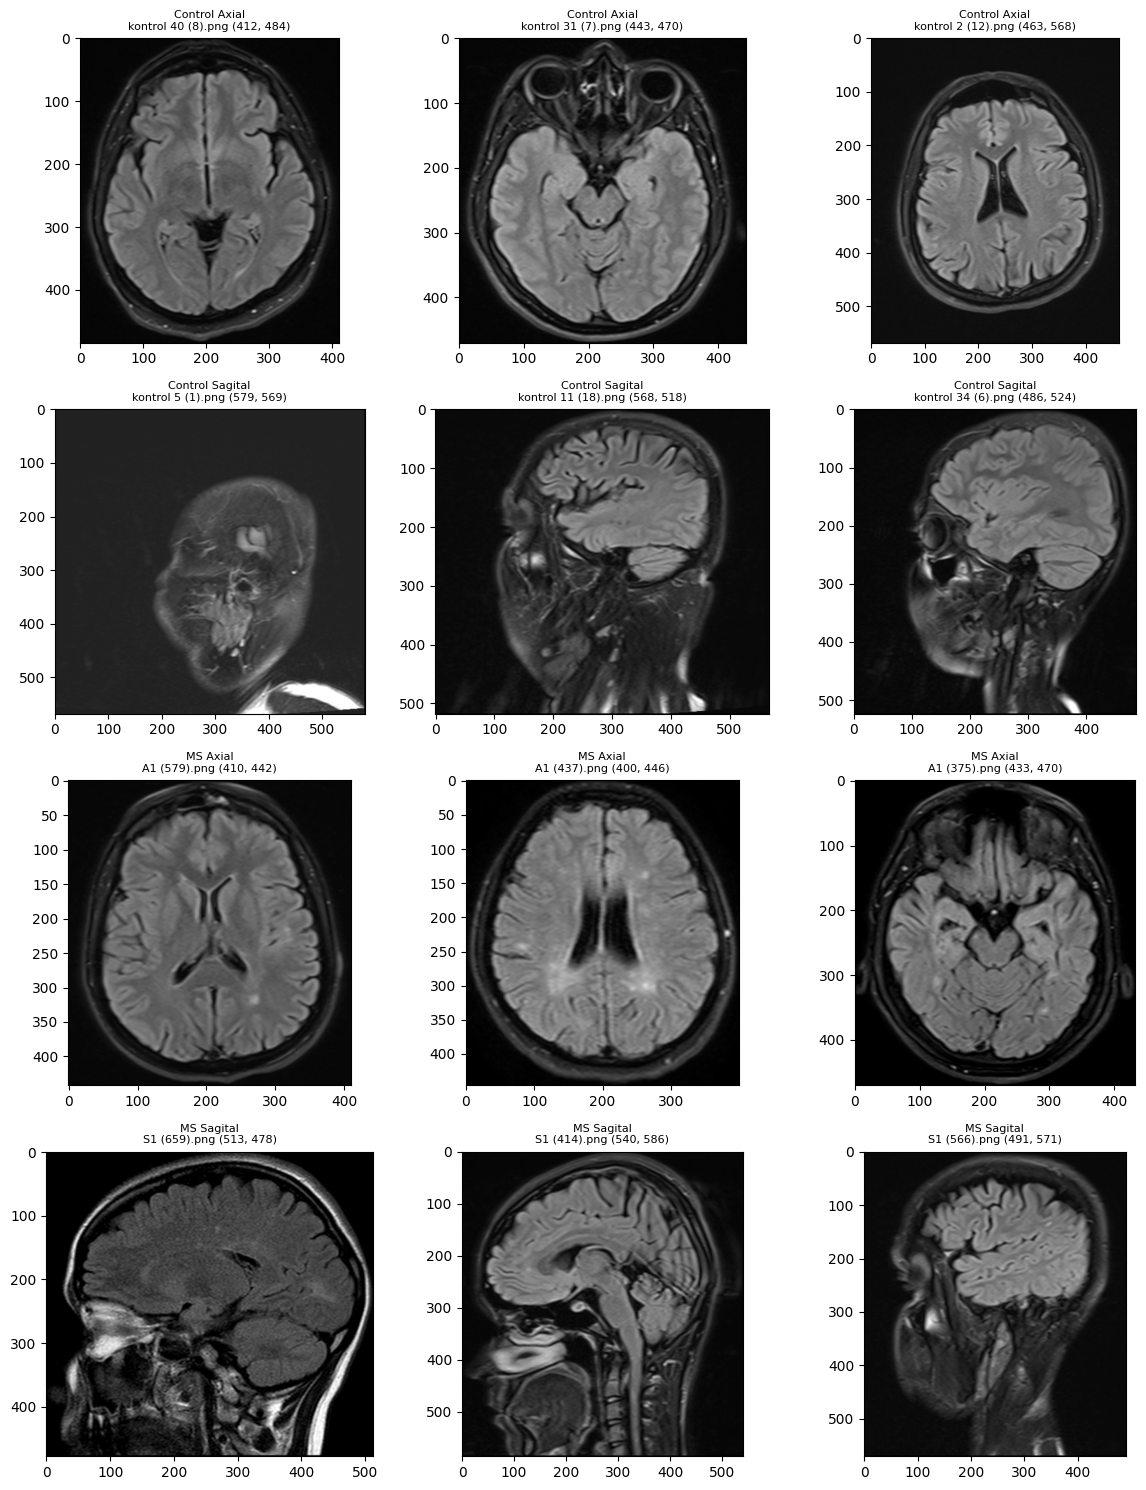

In [31]:
grupos = list(df.groupby(["Clase", "Corte"]))
fig, axs = plt.subplots(4, 3, figsize=(12, 15))
for fila, ((clase, corte), g) in zip(axs, grupos):
    for ax, (_, r) in zip(fila, g.sample(3, random_state=0).iterrows()):
        im = Image.open(r["ruta"])
        ax.imshow(im, cmap="gray")
        ax.set_title(f"{clase} {corte}\n{r['ruta'].name} {im.size}", fontsize=8)
plt.tight_layout()
plt.show()

# 4. Estructura del dataset: cuántos pacientes hay y en qué cortes.


//////////////////////////////////
Etiquetado de los datos de control
//////////////////////////////////


,Archivos,Con_ID,Sin_ID,Pacientes
Corte,,,,
Axial,1002,853,149,48
Sagital,1014,992,22,47


,Corte,Pacientes reales,Tramos por tamaño,% pacientes con un solo tamaño
0,Axial,48,602,4.2
1,Sagital,47,668,0.0


Pacientes  Media  Mediana  Min  Max
Clase   Corte                                       
Control Axial           48   17.8     18.0   15   20
        Sagital         47   21.1     22.0   11   24
MS      Axial          594    1.1      1.0    1   17
        Sagital        598    1.3      1.0    1   14

C:\Users\Bautista\AppData\Local\Temp\ipykernel_24256\3053493577.py:47: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  a.boxplot(datos, labels=["Control", "MS"]); a.set_title(corte); a.set_ylabel("Cortes por paciente")
C:\Users\Bautista\AppData\Local\Temp\ipykernel_24256\3053493577.py:47: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  a.boxplot(datos, labels=["Control", "MS"]); a.set_title(corte); a.set_ylabel("Cortes por paciente")


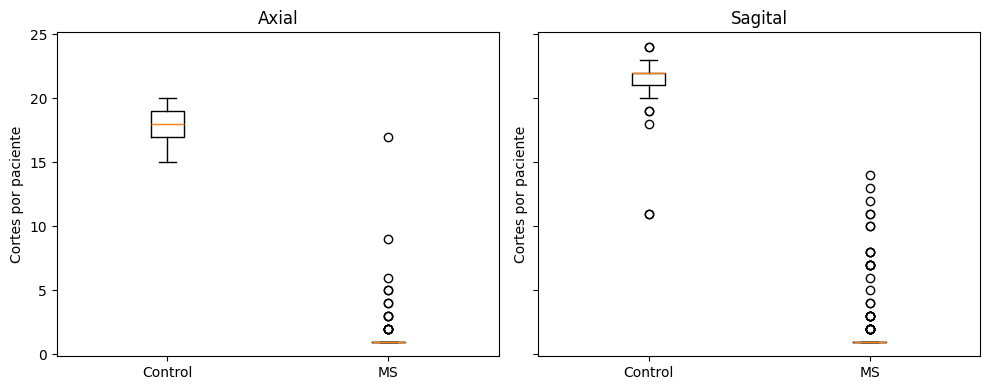

In [ ]:
import re
patron = re.compile(r"(\d*)\s*\((\d+)\)\s*$")
m = df["ruta"].apply(lambda p: patron.search(p.stem))

print("\n//////////////////////////////////")
print("Etiquetado de los datos de control")
print("//////////////////////////////////")

df["IdNombre"] = m.apply(lambda x: x.group(1) if x and x.group(1) else None)
df.loc[df["Clase"] == "MS", "IdNombre"] = None   # en MS "1" de A1/S1 es fijo, no es un ID

ctrl = df[df["Clase"] == "Control"]
display(ctrl.groupby("Corte").agg(
    Archivos=("ruta", "size"),
    Con_ID=("IdNombre", lambda s: s.notna().sum()),
    Sin_ID=("IdNombre", lambda s: s.isna().sum()),
    Pacientes=("IdNombre", "nunique")))

def tramos(g):
    cambio = (g[["ancho", "alto"]] != g[["ancho", "alto"]].shift()).any(axis=1)
    return cambio.cumsum()

print("\n|||||||||||||||||||||||||||||||||||||")
print("Varianción del tamaño de las imágenes")
print("|||||||||||||||||||||||||||||||||||||")
filas = []
for corte, g in df[(df["Clase"] == "Control") & df["IdNombre"].notna()].groupby("Corte"):
    g = g.assign(Id=g["IdNombre"].astype(int)).sort_values(["Id", "N"])
    g["Tramo"] = tramos(g)
    un_tamano = (g.groupby("Id")[["ancho", "alto"]].nunique().max(axis=1) == 1).mean() * 100
    filas.append({"Corte": corte, "Pacientes reales": g["Id"].nunique(),
                  "Tramos por tamaño": g["Tramo"].nunique(),
                  "% pacientes con un solo tamaño": round(un_tamano, 1)})
display(pd.DataFrame(filas))

# Paciente para todos
df["Paciente"] = None
for corte, g in df[df["Clase"] == "MS"].groupby("Corte"):
    g = g.sort_values("N")
    df.loc[g.index, "Paciente"] = "MS-" + corte[0] + "-" + tramos(g).astype(str)
mask = (df["Clase"] == "Control") & df["IdNombre"].notna()
df.loc[mask, "Paciente"] = "C-" + df.loc[mask, "Corte"].str[0] + "-" + df.loc[mask, "IdNombre"]

cortes_pac = df.dropna(subset=["Paciente"]).groupby(["Clase", "Corte", "Paciente"]).size().rename("Cortes").reset_index()
display(cortes_pac.groupby(["Clase", "Corte"])["Cortes"].agg(Pacientes="size", Media="mean", Mediana="median", Min="min", Max="max").round(1))

fig, ax = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for a, corte in zip(ax, ["Axial", "Sagital"]):
    datos = [cortes_pac[(cortes_pac["Clase"] == c) & (cortes_pac["Corte"] == corte)]["Cortes"] for c in ["Control", "MS"]]
    a.boxplot(datos, labels=["Control", "MS"]); a.set_title(corte); a.set_ylabel("Cortes por paciente")
plt.tight_layout()
plt.show()


&ensp; Cada archivo es un corte, no un paciente. Los 3427 archivos pertenecen a 131 sujetos (72 MS y 59 controles) y cada sujeto aporta una pila de cortes que recorre la cabeza.

- **Control:** el nombre trae el ID de paciente (`kontrol 17 (1)`: paciente 17, corte 1).
- **MS:** el nombre es `A1 (n)` / `S1 (n)`, con un contador continuo que mezcla a todos los pacientes. No trae ID.

&ensp; Los cortes consecutivos de un mismo paciente son muy parecidos. Si un clasificador se entrena con unos cortes de un paciente y se evalúa con otros del mismo paciente, el desempeño sale inflado (*data leakage*). La validación tiene que particionar **por paciente**, y para eso necesitamos un ID también en MS.

&ensp; Lo que hicimos fue: 

1. Extraer el ID y el número de corte de los nombres de Control.
2. Validar un criterio de reconstrucción: dentro de un paciente el recorte tiene tamaño constante, así que los saltos de tamaño en la secuencia marcan el cambio de paciente. Lo probamos en Control, donde conocemos la respuesta.
3. Aplicarlo a MS y comparar la cantidad de pacientes obtenida con los 72 esperados.
4. Comparar la cantidad de cortes por paciente entre clases (posible confusor).

**Supuesto a declarar en el informe:** en MS, los archivos están ordenados por paciente y los pacientes se reconstruyen por tramos de tamaño constante. Es una inferencia, no un dato del dataset.